# Подготовка данных для прогноза футбольного матча

Цель этого notebook — подготовить pre-match характеристики футбольных матчей
для дальнейшего статистического анализа: из исходных таблиц базы данных
построить один датасет "1 строка = 1 матч" с признаками, которые реально
были бы известны **до** начала матча.

Второй notebook, `2_football_statistical_analysis.ipynb`, уже использует
готовый результат этого этапа для EDA, статистических тестов и модели —
здесь эти темы не затрагиваются.

Путь по этому notebook: исходные данные → контроль качества → target →
принцип "никаких данных из будущего" → форма команды → сила стартового
состава → командные тактические характеристики → analytical sample →
итоговый датасет.


## Imports и пути

Все пути — относительно корня проекта, ноутбук рассчитан на запуск из `Team_project_3/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

In [2]:
PROJECT_ROOT = Path.cwd()
CSV_DIR = PROJECT_ROOT / "original_db + export" / "csv_export"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

MATCHES_CSV = CSV_DIR / "matches.csv"
LINEUPS_CSV = CSV_DIR / "lineups.csv"
PLAYER_ATTRIBUTES_CSV = CSV_DIR / "player_attributes.csv"
TEAM_ATTRIBUTES_CSV = CSV_DIR / "team_attributes.csv"

# Существующий результат полного технического ноутбука (football_match_analysis.ipynb) —
# используется только для сверки в конце, этот файл здесь НЕ перезаписывается.
EXISTING_INTERIM_CSV = INTERIM_DIR / "matches_with_form_squad_teamattrs.csv"

print("Все источники найдены:", all(p.exists() for p in [MATCHES_CSV, LINEUPS_CSV, PLAYER_ATTRIBUTES_CSV, TEAM_ATTRIBUTES_CSV]))

Все источники найдены: True


# 1. Исходные данные

Четыре таблицы из исходной базы (European Soccer Database), используемые
для подготовки признаков.


In [3]:
matches = pd.read_csv(MATCHES_CSV)
matches["date"] = pd.to_datetime(matches["date"], errors="coerce")

lineups = pd.read_csv(LINEUPS_CSV)
lineups["date"] = pd.to_datetime(lineups["date"])

player_attributes = pd.read_csv(PLAYER_ATTRIBUTES_CSV)
player_attributes["date"] = pd.to_datetime(player_attributes["date"])

team_attributes = pd.read_csv(TEAM_ATTRIBUTES_CSV)
team_attributes["date"] = pd.to_datetime(team_attributes["date"])

sources_summary = pd.DataFrame([
    {"dataset": "matches", "rows": len(matches), "entity": "1 строка = 1 матч",
     "purpose": "дата, команды, голы, league, season — база датасета и target"},
    {"dataset": "lineups", "rows": len(lineups), "entity": "1 строка = 1 игрок в стартовом составе 1 матча",
     "purpose": "кто играл — основа для силы состава"},
    {"dataset": "player_attributes", "rows": len(player_attributes), "entity": "1 строка = 1 исторический снимок FIFA-рейтинга игрока",
     "purpose": "overall_rating игрока на конкретную дату — сила состава"},
    {"dataset": "team_attributes", "rows": len(team_attributes), "entity": "1 строка = 1 исторический снимок стиля игры команды",
     "purpose": "тактические характеристики команды (атака/оборона)"},
])
sources_summary

,dataset,rows,entity,purpose
0,matches,25979,1 строка = 1 матч,"дата, команды, голы, league, season — база дат..."
1,lineups,542281,1 строка = 1 игрок в стартовом составе 1 матча,кто играл — основа для силы состава
2,player_attributes,183978,1 строка = 1 исторический снимок FIFA-рейтинга...,overall_rating игрока на конкретную дату — сил...
3,team_attributes,1458,1 строка = 1 исторический снимок стиля игры ко...,тактические характеристики команды (атака/обор...


**Вывод.** Все четыре таблицы связаны через `match_api_id`/`team_api_id`/
`player_api_id`. `matches` — центральная таблица (1 строка = 1 матч), три
остальные — источники pre-match признаков, которые ниже присоединяются к
ней через as-of join (снимок состояния строго до даты матча).


# 2. Качество матчей и аналитическое окно

Контроль качества `matches.csv` — только ключевые результаты аудита.


In [4]:
key_columns = ["date", "season", "league", "home_team_api_id", "away_team_api_id", "home_team_goal", "away_team_goal"]

quality_checks = {
    "матчей всего": len(matches),
    "пропусков в ключевых полях": int(matches[key_columns].isna().sum().sum()),
    "дублей по match_api_id": int(matches["match_api_id"].duplicated().sum()),
    "home_team_api_id == away_team_api_id": int((matches["home_team_api_id"] == matches["away_team_api_id"]).sum()),
    "отрицательные голы": int(((matches["home_team_goal"] < 0) | (matches["away_team_goal"] < 0)).sum()),
}
for check_name, value in quality_checks.items():
    print(f"{check_name}: {value}")

матчей всего: 25979
пропусков в ключевых полях: 0
дублей по match_api_id: 0
home_team_api_id == away_team_api_id: 0
отрицательные голы: 0


**Данные высокого качества**: пропусков в ключевых полях, дублей и
логических аномалий не найдено.

**Найденная проблема** — неполные данные по (лига, сезон): **Belgium
Jupiler League, сезон 2013/2014 — всего 12 матчей** вместо обычных ~240, все
со stage 1 по 6 (обрыв сезона в источнике, а не футбольный факт) → этот
сезон исключён из analytical/modeling выборки ниже.

**Аналитическое окно — сезоны 2010/2011–2015/2016.** Две причины:
1. более актуальный период для прогнозной задачи (легенда проекта — прогноз
   из точки 2017 года, более свежие сезоны точнее отражают текущее состояние
   команд);
2. `team_attributes` (раздел 7) структурно почти отсутствуют в 2008/2009 и
   сильно неполны в 2009/2010 (снимки начинаются только с 2010-02-22).


In [5]:
season_start_year = matches["season"].str.slice(0, 4).astype(int)
is_belgium_2013_2014 = (matches["league"] == "Belgium Jupiler League") & (matches["season"] == "2013/2014")
analytical_sample_mask = (season_start_year >= 2010) & (~is_belgium_2013_2014)

print("Матчей во всей базе:                                  ", len(matches))
print("Матчей начиная с сезона 2010/2011:                    ", int((season_start_year >= 2010).sum()))
print("Analytical sample (2010/2011-2015/2016, без Belgium 2013/2014):", int(analytical_sample_mask.sum()))

Матчей во всей базе:                                   25979
Матчей начиная с сезона 2010/2011:                     19423
Analytical sample (2010/2011-2015/2016, без Belgium 2013/2014): 19411


**Вывод.** Analytical sample — **19 411 матчей**. Исходные и interim CSV
физически **не обрезаются** — старые сезоны (2008/2009, 2009/2010) и
Belgium 2013/2014 остаются в данных как историческая база для rolling
form-признаков (раздел 5); фильтр применяется только при формировании
выборки для статистического анализа (следующий ноутбук).


# 3. Target: H / D / A

Целевая переменная будущей модели — исход матча с точки зрения хозяев поля.
Голы **текущего** матча используются только для того, чтобы определить его
собственный исход — не как predictor (predictor'ы — это всегда характеристики
**до** матча, разделы 5–7).


In [6]:
outcome_conditions = [matches["home_team_goal"] > matches["away_team_goal"], matches["home_team_goal"] == matches["away_team_goal"]]
matches["result"] = np.select(outcome_conditions, ["H", "D"], default="A")
matches["goal_difference"] = matches["home_team_goal"] - matches["away_team_goal"]

result_counts = matches["result"].value_counts()
result_share = (matches["result"].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({"count": result_counts, "share_%": result_share})

,count,share_%
result,,
H,11917,45.87
A,7466,28.74
D,6596,25.39


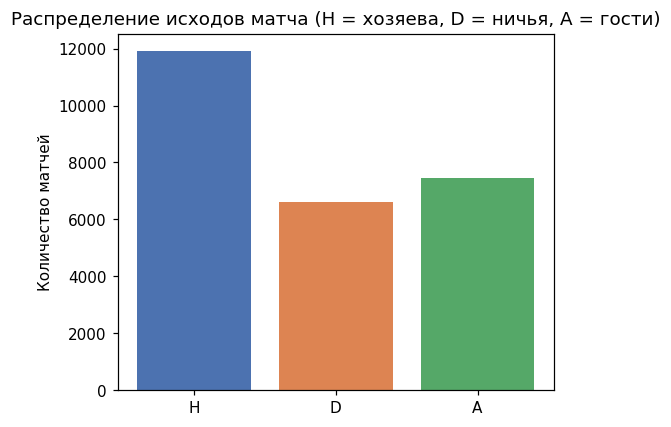

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
order = ["H", "D", "A"]
ax.bar(order, result_counts.reindex(order), color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Распределение исходов матча (H = хозяева, D = ничья, A = гости)")
ax.set_ylabel("Количество матчей")
plt.tight_layout()
plt.show()

**Вывод.** `result` посчитан без пропусков для всех 25 979 матчей. Победы
хозяев — самый частый исход (45.9%), это ожидаемый для футбола эффект
домашнего поля. `goal_difference` — вспомогательная переменная только для
EDA, не второй target.


# 4. Главный принцип: никаких данных из будущего

Все pre-match признаки ниже строятся по одному и тому же правилу: для
матча, который мы описываем, можно использовать только то, что было бы
реально известно **до** его начала. Два конкретных механизма:

**1. Историческая форма команды.** Текущий матч никогда не входит в
собственную историю — ряд сначала сдвигается на 1 матч назад (`shift(1)`),
и только потом считается скользящее окно (`rolling(...)`):

```
sort → groupby(team_api_id) → shift(1) → rolling(5)
```

Маленький пример на игрушечных данных — почему `shift(1)` обязателен:


In [8]:
demo = pd.Series([3, 3, 1, 0, 3, 3], name="points")  # W W D L W W — очки одной команды по хронологии
without_shift = demo.rolling(3).sum()          # НЕПРАВИЛЬНО: окно включает текущий матч
with_shift = demo.shift(1).rolling(3).sum()    # ПРАВИЛЬНО: окно строго из прошлых матчей

pd.DataFrame({"points": demo, "rolling_БЕЗ_shift (утечка)": without_shift, "rolling_С_shift (корректно)": with_shift})

,points,rolling_БЕЗ_shift (утечка),rolling_С_shift (корректно)
0,3,NaN,NaN
1,3,NaN,NaN
2,1,7.0,NaN
3,0,4.0,7.0
4,3,4.0,4.0
5,3,6.0,4.0


В последней строке демо: без `shift(1)` в сумму 3 последних матчей попал бы
и сам 6-й матч (значение включало бы его собственные 3 очка) — модель
"видела" бы результат матча, который как раз пытается предсказать. С
`shift(1)` окно смотрит строго на 3 предыдущих матча.

**2. Player/team attributes (сила состава, стиль игры).** Для каждого
матча используется только snapshot рейтинга/характеристик, существовавший
**строго до** даты матча:

```
attribute_date < match_date   (строго меньше, не <=)
```

Строгое неравенство, а не `<=`, — потому что в данных нет времени публикации
снимка относительно kick-off: если снимок датирован тем же днём, что и матч,
нельзя доказать, что он отражает состояние **до** игры.

Ниже, при построении каждого блока признаков (разделы 5–7), эти два правила
проверяются на реальных данных явным `assert`, а не только заявляются.


# 5. Форма команды

**Идея long table.** Каждый матч превращается в 2 строки — одна с точки
зрения хозяев, одна с точки зрения гостей. Так историю конкретной команды
(независимо от того, играла она дома или в гостях) можно получить простым
`groupby("team_api_id")`, отсортировав по дате.


In [9]:
home_rows = matches[[
    "match_api_id", "date", "season", "league", "home_team_api_id", "away_team_api_id",
    "home_team_goal", "away_team_goal", "result",
]].copy()
home_rows.columns = ["match_api_id", "date", "season", "league", "team_api_id", "opponent_api_id", "goals_scored", "goals_conceded", "result"]
home_rows["venue"] = "home"

away_rows = matches[[
    "match_api_id", "date", "season", "league", "away_team_api_id", "home_team_api_id",
    "away_team_goal", "home_team_goal", "result",
]].copy()
away_rows.columns = ["match_api_id", "date", "season", "league", "team_api_id", "opponent_api_id", "goals_scored", "goals_conceded", "result"]
away_rows["venue"] = "away"

team_matches = pd.concat([home_rows, away_rows], ignore_index=True)
team_matches["goal_difference"] = team_matches["goals_scored"] - team_matches["goals_conceded"]

print("1 строка на команду в 1 матче:", team_matches.shape, "(должно быть ровно 2 x", len(matches), ")")
team_matches.head(3)

1 строка на команду в 1 матче: (51958, 11) (должно быть ровно 2 x 25979 )


,match_api_id,date,season,league,team_api_id,opponent_api_id,goals_scored,goals_conceded,result,venue,goal_difference
0,492473,2008-08-17,2008/2009,Belgium Jupiler League,9987,9993,1,1,D,home,0
1,492474,2008-08-16,2008/2009,Belgium Jupiler League,10000,9994,0,0,D,home,0
2,492475,2008-08-16,2008/2009,Belgium Jupiler League,9984,8635,0,3,A,home,-3


Начисляем очки (3 за победу, 1 за ничью, 0 за поражение) и флаг победы, затем сортируем по хронологии внутри каждой команды.

In [10]:
is_win = ((team_matches["venue"] == "home") & (team_matches["result"] == "H")) | ((team_matches["venue"] == "away") & (team_matches["result"] == "A"))
is_draw = team_matches["result"] == "D"
team_matches["points"] = np.select([is_win, is_draw], [3, 1], default=0)
team_matches["win"] = (team_matches["points"] == 3).astype(int)

team_matches = team_matches.sort_values(["team_api_id", "date", "match_api_id"]).reset_index(drop=True)

**5 признаков формы**, все — строго по прошлым матчам команды
(`shift(1) → rolling(5, min_periods=1)`):

| Признак | Как считается |
| --- | --- |
| `points_last_5` | **сумма** очков за предыдущие максимум 5 матчей (0–15) |
| `win_rate_last_5` | среднее `win` (доля побед, 0–1) |
| `avg_goals_scored_last_5` | среднее забитых голов |
| `avg_goals_conceded_last_5` | среднее пропущенных голов |
| `avg_goal_difference_last_5` | средняя разница голов |

`points_last_5` — единственный признак-сумма (понятная величина "сколько
очков команда набрала за последние до 5 матчей"), остальные четыре —
средние за то же окно. `min_periods=1`: ранние матчи команды получают
признак по неполному окну вместо `NaN`, `matches_played_before` хранит
отдельно, на скольких матчах реально основано значение. `league` в
группировку не добавляем — в этих данных ни одна команда не встречается
более чем в одной лиге (проверено на уровне исходных данных), поэтому
риска смешать историю между лигами нет.


In [11]:
team_matches_grouped = team_matches.groupby("team_api_id", group_keys=False)
team_matches["matches_played_before"] = team_matches_grouped.cumcount()

form_source_columns = {
    "points": ("points_last_5", "sum"),
    "win": ("win_rate_last_5", "mean"),
    "goals_scored": ("avg_goals_scored_last_5", "mean"),
    "goals_conceded": ("avg_goals_conceded_last_5", "mean"),
    "goal_difference": ("avg_goal_difference_last_5", "mean"),
}

for source_column, (feature_name, aggregation) in form_source_columns.items():
    previous_values = team_matches_grouped[source_column].shift(1)
    rolling_window = previous_values.groupby(team_matches["team_api_id"]).rolling(5, min_periods=1)
    aggregated = rolling_window.sum() if aggregation == "sum" else rolling_window.mean()
    team_matches[feature_name] = aggregated.reset_index(level=0, drop=True)

form_feature_names = [name for name, _ in form_source_columns.values()]
team_matches[["team_api_id", "date", "matches_played_before", "points", "points_last_5", "win_rate_last_5"]].head(6)

,team_api_id,date,matches_played_before,points,points_last_5,win_rate_last_5
0,1601,2008-08-10,0,1,NaN,NaN
1,1601,2008-08-16,1,3,1.0,0.000000
2,1601,2008-08-22,2,3,4.0,0.500000
3,1601,2008-08-30,3,0,7.0,0.666667
4,1601,2008-09-12,4,3,7.0,0.500000
5,1601,2008-09-20,5,0,10.0,0.600000


Контрольный пример из постановки задачи: `W/W/D/L/W` (очки `3,3,1,0,3`) должно дать `points_last_5 = 10` (сумма), не `2.0` (среднее).

In [12]:
sample_points_last_5 = sum([3, 3, 1, 0, 3])
print("W/W/D/L/W -> points_last_5 (ожидаем 10, не 2.0):", sample_points_last_5)

# Anti-leakage проверка 1/3: окно строго из прошлых матчей, текущий матч в него не входит.
sample_team_id = team_matches["team_api_id"].iloc[0]
history = team_matches[team_matches["team_api_id"] == sample_team_id].reset_index(drop=True)
current_match, window = history.iloc[5], history.iloc[0:5]
assert (window["date"] < current_match["date"]).all()
assert current_match["match_api_id"] not in window["match_api_id"].values
assert history.loc[history["matches_played_before"] == 0, form_feature_names].isna().all().all()
print("OK: rolling-окно строго раньше текущего матча, текущий матч в своё окно не входит, у первого матча команды признаки формы - NaN")

W/W/D/L/W -> points_last_5 (ожидаем 10, не 2.0): 10
OK: rolling-окно строго раньше текущего матча, текущий матч в своё окно не входит, у первого матча команды признаки формы - NaN


Возвращаем признаки на уровень матча: `home_<feature>`, `away_<feature>`, `<feature>_diff = home - away`.

In [13]:
feature_columns_to_merge = ["match_api_id", "matches_played_before"] + form_feature_names
home_features = team_matches.loc[team_matches["venue"] == "home", feature_columns_to_merge].add_prefix("home_").rename(columns={"home_match_api_id": "match_api_id"})
away_features = team_matches.loc[team_matches["venue"] == "away", feature_columns_to_merge].add_prefix("away_").rename(columns={"away_match_api_id": "match_api_id"})

match_metadata_columns = [
    "id", "match_api_id", "country", "league", "season", "stage", "date",
    "home_team_api_id", "home_team_short", "home_team_long",
    "away_team_api_id", "away_team_short", "away_team_long",
    "home_team_goal", "away_team_goal", "result", "goal_difference",
]
matches_with_form = matches[match_metadata_columns].merge(home_features, on="match_api_id", how="left").merge(away_features, on="match_api_id", how="left")

for feature_name in form_feature_names:
    matches_with_form[f"{feature_name}_diff"] = matches_with_form[f"home_{feature_name}"] - matches_with_form[f"away_{feature_name}"]

print("matches_with_form:", matches_with_form.shape, "(25 979 строк, метаданные + 17 form-колонок)")

matches_with_form: (25979, 34) (25 979 строк, метаданные + 17 form-колонок)


**Вывод.** `matches_with_form` — 25 979 строк (1 на матч), с 17 новыми
form-колонками (`home_`/`away_`/`*_diff` для 5 признаков + `matches_played_before`).
Пропуски в `*_last_5`-колонках — честные (нет истории у команды), не
заполняются нулями.


# 6. Сила стартового состава

Для каждого игрока стартового состава берём его последний известный FIFA
`overall_rating`, известный **строго до** матча (`rating_date < match_date`) —
через `pd.merge_asof(direction="backward", allow_exact_matches=False)`. Перед
join устраняем дублирующиеся снимки (один и тот же игрок и дата — оставляем
строку с непустым `overall_rating`, если такая есть).


In [14]:
player_attributes_deduped = player_attributes.sort_values(
    ["player_api_id", "date", "overall_rating"], na_position="last"
).drop_duplicates(subset=["player_api_id", "date"], keep="first")

player_ratings = player_attributes_deduped[["player_api_id", "date", "overall_rating"]].rename(columns={"date": "rating_date"}).sort_values("rating_date")
lineups_for_join = lineups.rename(columns={"date": "match_date"}).sort_values("match_date")

player_ratings_asof = pd.merge_asof(
    lineups_for_join, player_ratings,
    left_on="match_date", right_on="rating_date", by="player_api_id",
    direction="backward", allow_exact_matches=False,
)
player_ratings_asof["player_rating_age_days"] = (player_ratings_asof["match_date"] - player_ratings_asof["rating_date"]).dt.days

print("Строк lineups:", len(lineups), "| строк после as-of join:", len(player_ratings_asof), "(join не размножил строки)")
print("Рейтинг найден для:", int(player_ratings_asof["overall_rating"].notna().sum()), "из", len(player_ratings_asof), "строк состава")

Строк lineups: 542281 | строк после as-of join: 542281 (join не размножил строки)
Рейтинг найден для: 542281 из 542281 строк состава


In [15]:
# Anti-leakage проверка 2/3: rating_date строго раньше match_date для всех найденных рейтингов.
valid_ratings = player_ratings_asof["overall_rating"].notna()
assert (player_ratings_asof.loc[valid_ratings, "rating_date"] < player_ratings_asof.loc[valid_ratings, "match_date"]).all()
print("OK: rating_date < match_date для 100% найденных рейтингов игроков")

OK: rating_date < match_date для 100% найденных рейтингов игроков


Агрегируем на уровень (матч, сторона): **средний** рейтинг найденных игроков
(не сумма — чувствительна к неполным составам), плюс coverage состава.
`lineup_players_known`/`players_with_rating` считаются через число
**уникальных** `player_api_id` (в данных найден 1 случай, когда один игрок
дважды учтён в одном составе одного матча — учёт уникальных `player_api_id`
устраняет эту проблему без правки сырых данных).


In [16]:
def aggregate_squad_features(group):
    lineup_players_known = group["player_api_id"].nunique()
    rated_players = group[group["overall_rating"].notna()]
    players_with_rating = rated_players["player_api_id"].nunique()
    return pd.Series({
        "lineup_players_known": lineup_players_known,
        "players_with_rating": players_with_rating,
        "mean_overall_rating": rated_players["overall_rating"].mean(),
        "mean_player_rating_age_days": rated_players["player_rating_age_days"].mean(),
        "max_player_rating_age_days": rated_players["player_rating_age_days"].max(),
    })


squad_features = player_ratings_asof.groupby(["match_api_id", "side"]).apply(aggregate_squad_features, include_groups=False).reset_index()
squad_features["rating_coverage"] = squad_features["players_with_rating"] / squad_features["lineup_players_known"]
squad_features["lineup_coverage"] = squad_features["lineup_players_known"] / 11

squad_feature_columns = ["match_api_id", "lineup_players_known", "players_with_rating", "mean_overall_rating", "mean_player_rating_age_days", "max_player_rating_age_days", "rating_coverage", "lineup_coverage"]
home_squad = squad_features.loc[squad_features["side"] == "home", squad_feature_columns].add_prefix("home_").rename(columns={"home_match_api_id": "match_api_id"})
away_squad = squad_features.loc[squad_features["side"] == "away", squad_feature_columns].add_prefix("away_").rename(columns={"away_match_api_id": "match_api_id"})

matches_with_form_and_squad = matches_with_form.merge(home_squad, on="match_api_id", how="left").merge(away_squad, on="match_api_id", how="left")
matches_with_form_and_squad["overall_rating_diff"] = matches_with_form_and_squad["home_mean_overall_rating"] - matches_with_form_and_squad["away_mean_overall_rating"]

# Аналитический флаг надёжности squad rating: не менее 10 из 11 известных игроков с каждой стороны.
matches_with_form_and_squad["squad_rating_reliable"] = (
    (matches_with_form_and_squad["home_lineup_players_known"] >= 10) & (matches_with_form_and_squad["away_lineup_players_known"] >= 10)
)

print("matches_with_form_and_squad:", matches_with_form_and_squad.shape)
print("Матчей с рейтингом обеих команд:", int((matches_with_form_and_squad["home_mean_overall_rating"].notna() & matches_with_form_and_squad["away_mean_overall_rating"].notna()).sum()))
print("squad_rating_reliable (>=10 из 11 с каждой стороны):", round(matches_with_form_and_squad["squad_rating_reliable"].mean() * 100, 2), "%")

matches_with_form_and_squad: (25979, 50)
Матчей с рейтингом обеих команд: 25221
squad_rating_reliable (>=10 из 11 с каждой стороны): 91.5 %


**Вывод.** Составы доступны почти для всей базы (758 из 25 979 матчей — 2.9%
— вообще без данных о составе). Для надёжного аналитического сравнения силы
состава используется `squad_rating_reliable` (порог `>=10` игроков из 11 с
каждой стороны) — покрывает **≈91.5%** всей базы и, как показано в разделе 8,
**≈95.88%** analytical sample (2010/2011+).


# 7. Team attributes

`team_attributes` — кандидаты для описания игрового стиля команды. Взяты
**6 числовых характеристик**: `buildUpPlaySpeed`, `buildUpPlayPassing`,
`chanceCreationPassing`, `chanceCreationShooting`, `defencePressure`,
`defenceAggression` (остальные числовые/категориальные поля — либо с
большой долей пропусков, либо избыточны при наличии числовой версии). Для
каждой — `home`/`away`/`diff`, тот же as-of join (`team_attribute_date <
match_date`), выполненный отдельно для home и away.


In [17]:
columns_except_id = [c for c in team_attributes.columns if c != "id"]
team_attributes_deduped = team_attributes.drop_duplicates(subset=columns_except_id, keep="first")

numeric_team_features = ["buildUpPlaySpeed", "buildUpPlayPassing", "chanceCreationPassing", "chanceCreationShooting", "defencePressure", "defenceAggression"]
team_attributes_for_join = team_attributes_deduped[["team_api_id", "date"] + numeric_team_features].rename(columns={"date": "team_attribute_date"}).sort_values("team_attribute_date")
matches_sorted_by_date = matches_with_form_and_squad.sort_values("date")


def asof_join_team_attrs(side_column):
    joined = pd.merge_asof(
        matches_sorted_by_date[["match_api_id", "date", side_column]],
        team_attributes_for_join,
        left_on="date", right_on="team_attribute_date", left_by=side_column, right_by="team_api_id",
        direction="backward", allow_exact_matches=False,
    ).sort_values("match_api_id").reset_index(drop=True)
    joined["team_attr_age_days"] = (joined["date"] - joined["team_attribute_date"]).dt.days
    return joined


home_team_attrs = asof_join_team_attrs("home_team_api_id")
away_team_attrs = asof_join_team_attrs("away_team_api_id")

print("home_team_attrs:", home_team_attrs.shape, "| away_team_attrs:", away_team_attrs.shape, "(оба должны совпадать с числом матчей)")

home_team_attrs: (25979, 12) | away_team_attrs: (25979, 12) (оба должны совпадать с числом матчей)


In [18]:
# Anti-leakage проверка 3/3: team_attribute_date строго раньше даты матча, для обеих сторон.
valid_home, valid_away = home_team_attrs["team_attribute_date"].notna(), away_team_attrs["team_attribute_date"].notna()
assert (home_team_attrs.loc[valid_home, "team_attribute_date"] < home_team_attrs.loc[valid_home, "date"]).all()
assert (away_team_attrs.loc[valid_away, "team_attribute_date"] < away_team_attrs.loc[valid_away, "date"]).all()
print("OK: team_attribute_date < match_date для 100% найденных снимков (home и away)")
print()
print("Проверки пройдены, данных из будущего нет.")

OK: team_attribute_date < match_date для 100% найденных снимков (home и away)

Проверки пройдены, данных из будущего нет.


In [19]:
home_renamed = home_team_attrs[["match_api_id"] + numeric_team_features + ["team_attr_age_days"]].add_prefix("home_").rename(columns={"home_match_api_id": "match_api_id"})
away_renamed = away_team_attrs[["match_api_id"] + numeric_team_features + ["team_attr_age_days"]].add_prefix("away_").rename(columns={"away_match_api_id": "match_api_id"})
team_attr_features = home_renamed.merge(away_renamed, on="match_api_id", how="inner")

for feature_name in numeric_team_features:
    team_attr_features[f"{feature_name}_diff"] = team_attr_features[f"home_{feature_name}"] - team_attr_features[f"away_{feature_name}"]

both_sides_coverage = (home_team_attrs["buildUpPlaySpeed"].notna() & away_team_attrs["buildUpPlaySpeed"].notna())
print("team_attr_features:", team_attr_features.shape)
print("Coverage team_attributes (обе команды, вся база):", round(both_sides_coverage.mean() * 100, 2), "%")

team_attr_features: (25979, 21)
Coverage team_attributes (обе команды, вся база): 74.48 %


**Вывод.** Глобальный coverage (обе команды) заметно ниже, чем у силы
состава — структурный разрыв: `team_attributes` начинаются только с
2010-02-22, поэтому 2008/2009 имеет 0% coverage, 2009/2010 — тоже сильно
неполный. Начиная с 2010/2011 coverage стабилизируется на 93–96% по
сезонам — это и есть техническое обоснование аналитического окна (раздел
2). Признаки сохранены для последующего статистического анализа — этот
ноутбук не делает вывод, влияют ли они на результат.


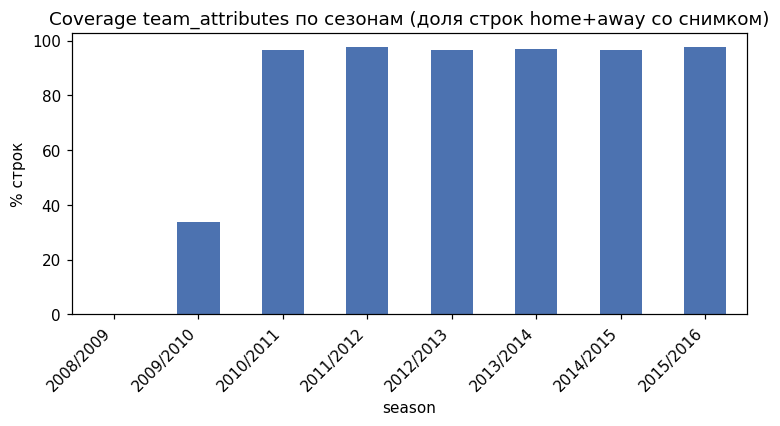

In [20]:
coverage_by_season = pd.concat([
    home_team_attrs.merge(matches[["match_api_id", "season"]], on="match_api_id")[["season"]].assign(has=home_team_attrs["buildUpPlaySpeed"].notna().values),
    away_team_attrs.merge(matches[["match_api_id", "season"]], on="match_api_id")[["season"]].assign(has=away_team_attrs["buildUpPlaySpeed"].notna().values),
]).groupby("season")["has"].mean().mul(100)

fig, ax = plt.subplots(figsize=(7, 4))
coverage_by_season.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Coverage team_attributes по сезонам (доля строк home+away со снимком)")
ax.set_ylabel("% строк")
ax.set_xlabel("season")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 8. Итоговый match-level dataset

Собираем все три блока признаков (форма, сила состава, team attributes)
в один датасет — по структуре и содержанию эквивалентный
`data/interim/matches_with_form_squad_teamattrs.csv`, уже созданному в
полном техническом ноутбуке (`football_match_analysis.ipynb`).

**Этот файл здесь не перезаписывается** — ниже собранный в памяти датасет
только **сверяется** с уже существующим файлом (shape и ключевые колонки),
чтобы подтвердить, что сокращённый ноутбук воспроизводит ту же самую
подготовку данных, а не новую версию pipeline.


In [21]:
matches_with_form_squad_teamattrs_new = matches_with_form_and_squad.merge(team_attr_features, on="match_api_id", how="left")

print("Новый (в памяти) датасет:", matches_with_form_squad_teamattrs_new.shape)
print("match_api_id уникален:", matches_with_form_squad_teamattrs_new["match_api_id"].is_unique)

Новый (в памяти) датасет: (25979, 70)
match_api_id уникален: True


Старые сезоны (2008/2009, 2009/2010) и Belgium 2013/2014 **не удаляются** из
этого файла — они остаются исторической базой для rolling form-признаков на
границе окна (например, первые матчи сезона 2010/2011 используют предыдущие
матчи команды из 2009/2010 при расчёте `points_last_5`). Ограничение окна
(раздел 2) применяется только при формировании analytical/modeling выборки
в следующем ноутбуке.

### Сверка с существующим interim-файлом


In [22]:
existing = pd.read_csv(EXISTING_INTERIM_CSV)
existing["date"] = pd.to_datetime(existing["date"])

new_df = matches_with_form_squad_teamattrs_new.sort_values("match_api_id").reset_index(drop=True)
existing_sorted = existing.sort_values("match_api_id").reset_index(drop=True)

diff_features_to_check = [f"{name}_diff" for name in form_feature_names] + ["overall_rating_diff"] + [f"{name}_diff" for name in numeric_team_features]

comparison_checks = {
    "число строк совпадает": len(new_df) == len(existing_sorted),
    "match_api_id совпадает": (new_df["match_api_id"].values == existing_sorted["match_api_id"].values).all(),
    "result совпадает": (new_df["result"].values == existing_sorted["result"].values).all(),
}
for feature in diff_features_to_check:
    comparison_checks[f"{feature} совпадает (tolerance, NaN-aware)"] = bool(
        np.allclose(new_df[feature].to_numpy(dtype=float), existing_sorted[feature].to_numpy(dtype=float), atol=1e-6, equal_nan=True)
    )

for check_name, passed in comparison_checks.items():
    print(("OK  " if passed else "FAIL") + " - " + check_name)

assert all(comparison_checks.values()), "Сокращённый ноутбук воспроизвёл датасет иначе, чем существующий interim-файл"
print()
print("Датасет полностью совпадает с уже существующим data/interim/matches_with_form_squad_teamattrs.csv")
print("(файл НЕ перезаписан этим ноутбуком)")

OK   - число строк совпадает
OK   - match_api_id совпадает
OK   - result совпадает
OK   - points_last_5_diff совпадает (tolerance, NaN-aware)
OK   - win_rate_last_5_diff совпадает (tolerance, NaN-aware)
OK   - avg_goals_scored_last_5_diff совпадает (tolerance, NaN-aware)
OK   - avg_goals_conceded_last_5_diff совпадает (tolerance, NaN-aware)
OK   - avg_goal_difference_last_5_diff совпадает (tolerance, NaN-aware)
OK   - overall_rating_diff совпадает (tolerance, NaN-aware)
OK   - buildUpPlaySpeed_diff совпадает (tolerance, NaN-aware)
OK   - buildUpPlayPassing_diff совпадает (tolerance, NaN-aware)
OK   - chanceCreationPassing_diff совпадает (tolerance, NaN-aware)
OK   - chanceCreationShooting_diff совпадает (tolerance, NaN-aware)
OK   - defencePressure_diff совпадает (tolerance, NaN-aware)
OK   - defenceAggression_diff совпадает (tolerance, NaN-aware)

Датасет полностью совпадает с уже существующим data/interim/matches_with_form_squad_teamattrs.csv
(файл НЕ перезаписан этим ноутбуком)


# 9. Какие признаки переданы на статистический анализ

Итог этого ноутбука с точки зрения того, что дальше используется в
`football_statistical_analysis.ipynb`. Статистический отбор конкретных
характеристик (какие именно 2 признака стали финальными) в этот ноутбук не
входит — только какие группы признаков вообще технически готовы к передаче.


In [23]:
feature_summary = pd.DataFrame([
    {"feature_group": "Форма (form)", "examples": "points_last_5_diff, avg_goal_difference_last_5_diff, ...", "pre_match": "да", "coverage": "~99.6%", "status": "передано в анализ"},
    {"feature_group": "Сила состава (squad)", "examples": "mean_overall_rating / overall_rating_diff", "pre_match": "да", "coverage": "~95.9% (squad_rating_reliable)", "status": "передано в анализ"},
    {"feature_group": "Командный стиль (team style)", "examples": "buildUpPlaySpeed_diff, defencePressure_diff, ...", "pre_match": "да", "coverage": "~94.1%", "status": "передано в анализ"},
    {"feature_group": "Постматчевая XML-статистика", "examples": "удары, угловые, карточки текущего матча", "pre_match": "нет", "coverage": "-", "status": "исключено (post-match leakage)"},
    {"feature_group": "Букмекерские коэффициенты", "examples": "pre-match odds", "pre_match": "да", "coverage": "-", "status": "не использовались в MVP feature set"},
])
feature_summary

,feature_group,examples,pre_match,coverage,status
0,Форма (form),"points_last_5_diff, avg_goal_difference_last_5...",да,~99.6%,передано в анализ
1,Сила состава (squad),mean_overall_rating / overall_rating_diff,да,~95.9% (squad_rating_reliable),передано в анализ
2,Командный стиль (team style),"buildUpPlaySpeed_diff, defencePressure_diff, ...",да,~94.1%,передано в анализ
3,Постматчевая XML-статистика,"удары, угловые, карточки текущего матча",нет,-,исключено (post-match leakage)
4,Букмекерские коэффициенты,pre-match odds,да,-,не использовались в MVP feature set


# 10. Итог подготовки данных

- Исходные данные проверены (`matches.csv`, `lineups.csv`, `player_attributes.csv`, `team_attributes.csv`) — пропусков и дублей в ключевых полях не найдено.
- Исторические признаки построены без утечки данных: форма считается только по прошлым матчам команды (`shift(1) → rolling(...)`), рейтинги игроков и team attributes присоединены строго as-of (`attribute_date < match_date`).
- Сформирован единый match-level dataset (`matches_with_form_squad_teamattrs`, 25 979 строк) с метаданными, target, form-признаками, силой состава и командным стилем.
- Analytical sample для статистического анализа и модели — **19 411 матчей** (сезоны 2010/2011–2015/2016, без Belgium Jupiler League 2013/2014).
- Статистический отбор характеристик и прогнозная модель выполнены в `football_statistical_analysis.ipynb`.
